---
title: Onset of ergodicity across scales
description: Run and analyze a 64-qubit Floquet experiment on an IBM Quantum Nighthawk processor, from entropy estimators to noise learning and error mitigation.
---

{/* cspell:ignore Floquet sublayers sublayer Néel edgecolor edgecolors Parseval ddof iprs dashdot thermalized thermalization debiased sharey unflip */}

# Onset of ergodicity across scales

This notebook walks through how to run and analyze the experiments in *Onset of Ergodicity Across Scales on a Digital Quantum Processor* [[arXiv:2603.12236](https://arxiv.org/abs/2603.12236)]: from the model to the circuits, from bitstrings to entropies, from noisy data to mitigated results, and from a 16-qubit simulation to a 64-qubit run on an IBM Quantum&reg; Nighthawk processor. All the code is here, and each function is defined where it is first needed.

| Time | Section |
|---|---|
| 0–1 min | Setup |
| 1–6 min | 1. From the model to a circuit |
| 6–12 min | 2. What to measure and how to estimate it |
| 12–19 min | 3. Noise, and how to undo it |
| 19–24 min | 4. Run at scale |
| 24–33 min | 5. The hardware data |
| 33–35 min | Wrap-up |

**Following along.** Run the cells from top to bottom. No IBM Quantum account is needed; the cells that submit hardware jobs are switched off, and section 5 analyzes a saved hardware run, which the setup cell downloads to `data/`. Questions for discussion are marked **Question**; try to answer before you open the answer.

## Setup

Requires Python 3.12 or later and the following packages:

- Qiskit SDK v2.5 or later, with [visualization](/docs/api/qiskit/visualization) support
- Qiskit Runtime v0.49 or later (`pip install qiskit-ibm-runtime`)
- Qiskit Aer v0.17 or later (`pip install qiskit-aer`)
- [Samplomatic](https://github.com/Qiskit/samplomatic) v0.21 or later (`pip install samplomatic`)
- NumPy and Matplotlib

The setup cell also downloads the saved hardware run and MPS references (about 9 MB) to `data/`, unless they are already there.

In [1]:
from math import comb
from pathlib import Path
from urllib.request import urlretrieve

import matplotlib.pyplot as plt
import numpy as np
from qiskit import ClassicalRegister, QuantumCircuit, QuantumRegister
from qiskit.primitives import StatevectorSampler
from qiskit.quantum_info import (
    PauliLindbladMap,
    QubitSparsePauli,
    Statevector,
)
from qiskit.transpiler import generate_preset_pass_manager
from qiskit_aer import AerSimulator
from qiskit_aer.noise import NoiseModel, ReadoutError, depolarizing_error
from qiskit_aer.primitives import SamplerV2 as AerSampler

RUN_ON_HARDWARE = (
    False  # True submits the 8x8 jobs in section 4 (needs Nighthawk access)
)
COMPUTE_MPS_REFERENCES = False  # True recomputes the MPS references in section 5 (about 18 minutes)

# Download the saved hardware run and MPS references, unless they are already in data/
data_url = "https://raw.githubusercontent.com/Qiskit/documentation/main/datasets/tutorials/onset-of-ergodicity"
Path("data").mkdir(exist_ok=True)
for name in ("hardware_run.npz", "mps_references_all.npz"):
    if not Path("data", name).exists():
        urlretrieve(f"{data_url}/{name}", Path("data", name))

## 1. From the model to a circuit

### The two-qubit gate

Every bond $(i, j)$ of the lattice gets the same two-qubit gate, made of a Heisenberg entangler followed by random fields:

$$
\Large
U_{ij} =  e^{iJ(X_iX_j + Y_iY_j + Z_iZ_j)}\; e^{i(h_i Z_i + h_j Z_j)}
$$

with $h$ drawn uniformly from $[-\pi/2, \pi/2]$ for every gate.

> **Question.** How would you decompose $U_{ij}$ into gates the hardware can run?

<Accordion>
<AccordionItem title="Answer">

**The fields** are easy. $e^{ihZ}$ is a single-qubit rotation $R_Z(-2h)$ on each qubit.

**The entangler** is the hard part. $XX$, $YY$ and $ZZ$ commute, so it factors into three rotations, $R_{XX}$, $R_{YY}$ and $R_{ZZ}$. Each takes two CNOTs, which makes six CNOTs per gate.

There is a better way. Any two-qubit gate can be built from at most three CNOTs and single-qubit rotations. The optimal circuit starts from the form $e^{i(aXX + bYY + cZZ)}$, and this entangler already has that form with $a = b = c = J$. So it maps straight onto three CNOTs, and the single-qubit angles are linear in $J$. The experiment code builds the gate this way.

On hardware, every two-qubit gate adds noise, so halving the CNOT count matters.

</AccordionItem>
</Accordion>

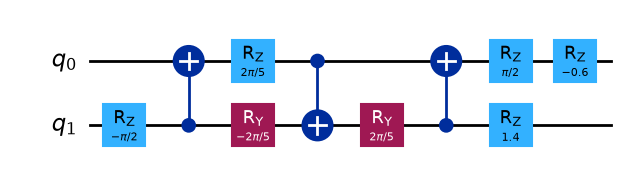

In [2]:
def xxyyzz_gate(circuit, coupling, i, j):
    # exp(iJ(XX + YY + ZZ)) with three CNOTs; only the rotation angles depend on J
    circuit.rz(-np.pi / 2, j)
    circuit.cx(j, i)
    circuit.rz(np.pi / 2 - 2 * coupling, i)
    circuit.ry(2 * coupling - np.pi / 2, j)
    circuit.cx(i, j)
    circuit.ry(np.pi / 2 - 2 * coupling, j)
    circuit.cx(j, i)
    circuit.rz(np.pi / 2, i)


def heisenberg_gate(circuit, coupling, i, j, h_i, h_j):
    # The entangler first, then the random fields exp(i h Z)
    xxyyzz_gate(circuit, coupling, i, j)
    circuit.rz(-2 * h_i, i)
    circuit.rz(-2 * h_j, j)


h_i, h_j = 0.3, -0.7
gate = QuantumCircuit(2)
heisenberg_gate(gate, 0.05 * np.pi, 0, 1, h_i, h_j)
gate.draw("mpl")

### The brickwork and the Floquet cycle

The gates tile the square lattice in four *sublayers* of non-overlapping bonds, a brickwork: horizontal bonds starting on even columns, then odd columns, then vertical bonds starting on even rows, then odd rows. Qubit $y \cdot L_x + x$ sits at site $(x, y)$.

In [3]:
def brickwork_layers(num_cols, num_rows):
    # Bonds of the square lattice, in the four sublayers of the brickwork
    def qubit(x, y):
        return y * num_cols + x

    layers = []
    for p in (0, 1):  # horizontal bonds starting on even, then odd, columns
        layers.append(
            [
                (qubit(x, y), qubit(x + 1, y))
                for y in range(num_rows)
                for x in range(p, num_cols - 1, 2)
            ]
        )
    for p in (0, 1):  # vertical bonds starting on even, then odd, rows
        layers.append(
            [
                (qubit(x, y), qubit(x, y + 1))
                for y in range(p, num_rows - 1, 2)
                for x in range(num_cols)
            ]
        )
    return layers


brickwork_layers(4, 4)

[[(0, 1), (2, 3), (4, 5), (6, 7), (8, 9), (10, 11), (12, 13), (14, 15)],
 [(1, 2), (5, 6), (9, 10), (13, 14)],
 [(0, 4), (1, 5), (2, 6), (3, 7), (8, 12), (9, 13), (10, 14), (11, 15)],
 [(4, 8), (5, 9), (6, 10), (7, 11)]]

The four sublayers make one *Floquet cycle*. The cycle repeats $n_F$ times with **the same fields**, so the dynamics are random in space and periodic in time. The circuit starts from the Néel state, and $n_F$ is half the side length of the lattice.

The next cell draws one Floquet cycle of the $8 \times 8$ hardware lattice, sublayer by sublayer, with the fields of the hardware run, in the style of Figure 5 of the paper. Thick bonds are the gates of each sublayer. Each qubit a gate acts on is colored by the random field $h$ it then receives, and idle qubits are white. The arrows show the Néel initial state, with $\uparrow$ for $|0\rangle$. The paper's figure applies the vertical sublayers first; neither order is expected to change the physics.

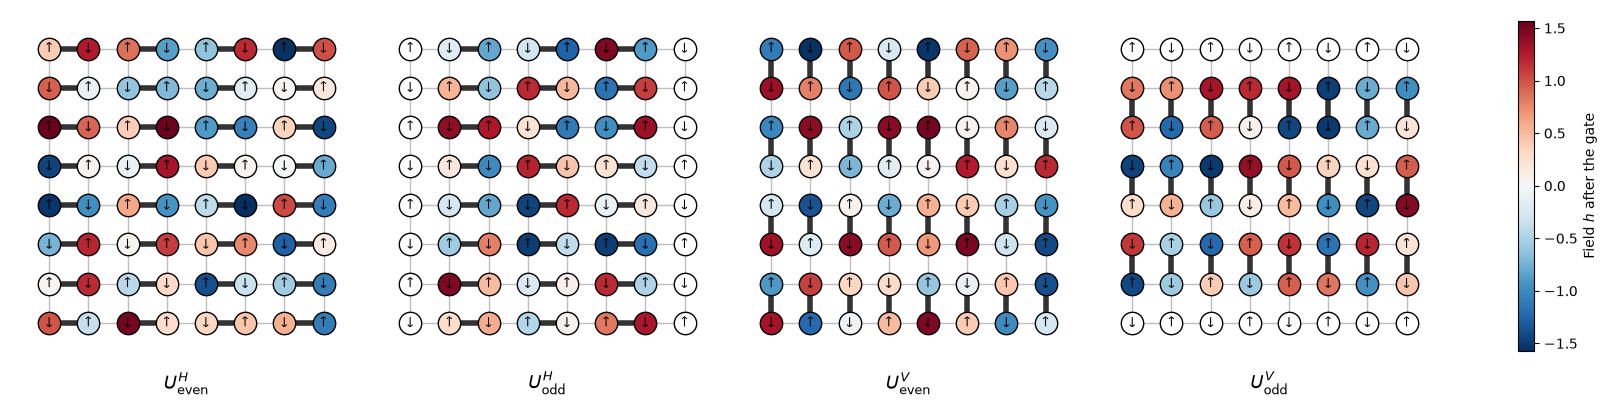

In [4]:
# circuit structure, 8x8 system:
side = 8
all_bonds = [bond for layer in brickwork_layers(side, side) for bond in layer]


# get the disorder parameters for a given system:
def sample_disorder(num_cols, num_rows, rng):
    # One pair of fields (h_i, h_j) per gate, reused in every Floquet cycle
    return [
        [
            (bond, tuple(rng.uniform(-np.pi / 2, np.pi / 2, 2)))
            for bond in layer
        ]
        for layer in brickwork_layers(num_cols, num_rows)
    ]


# build the structure for the 8x8 system
example_disorder = sample_disorder(
    side, side, np.random.default_rng(7)
)  # the hardware fields (section 4)
titles = [
    r"$U^H_\mathrm{even}$",
    r"$U^H_\mathrm{odd}$",
    r"$U^V_\mathrm{even}$",
    r"$U^V_\mathrm{odd}$",
]
norm = plt.Normalize(-np.pi / 2, np.pi / 2)
cmap = plt.get_cmap("RdBu_r")

fig, axes = plt.subplots(1, 4, figsize=(16, 4.8), layout="constrained")
for ax, title, sublayer in zip(axes, titles, example_disorder):
    for i, j in all_bonds:
        ax.plot(
            [i % side, j % side],
            [i // side, j // side],
            color="0.75",
            lw=1,
            zorder=0,
        )
    fields = {}
    for (i, j), (h_i, h_j) in sublayer:
        ax.plot(
            [i % side, j % side],
            [i // side, j // side],
            color="0.2",
            lw=4,
            zorder=1,
        )
        fields[i], fields[j] = h_i, h_j
    for q in range(side * side):
        x, y = q % side, q // side
        ax.scatter(
            x,
            y,
            s=260,
            color=cmap(norm(fields[q])) if q in fields else "white",
            edgecolor="black",
            zorder=2,
        )
        ax.text(
            x,
            y,
            "↓" if (x + y) % 2 else "↑",
            ha="center",
            va="center",
            fontsize=9,
            zorder=3,
        )
    ax.set_aspect("equal")
    ax.set_xlim(-1, side)  # padding, so the panels read as separate steps
    ax.set_ylim(side, -1)
    ax.axis("off")
    ax.set_title(title, y=-0.1, fontsize=13)
fig.colorbar(
    plt.cm.ScalarMappable(norm=norm, cmap=cmap),
    ax=axes,
    shrink=0.7,
    label="Field $h$ after the gate",
)
plt.show()

Define the initial state.

In [5]:
# initial state
def neel_state(circuit, num_cols, num_rows, layout):
    for y in range(num_rows):
        for x in range(num_cols):
            if (x + y) % 2 == 1:
                circuit.x(layout[y * num_cols + x])

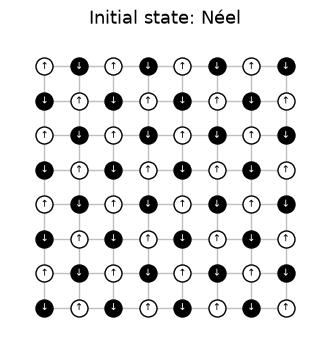

In [6]:
# The initial Néel state: |1⟩ (black, ↓) on odd sites, |0⟩ (white, ↑) on even sites

fig, ax = plt.subplots(figsize=(4, 4.4))
for i, j in all_bonds:
    ax.plot(
        [i % side, j % side],
        [i // side, j // side],
        color="0.75",
        lw=1,
        zorder=0,
    )
for q in range(side * side):
    x, y = q % side, q // side
    excited = (x + y) % 2 == 1
    ax.scatter(
        x,
        y,
        s=150,
        color="black" if excited else "white",
        edgecolor="black",
        zorder=2,
    )
    ax.text(
        x,
        y,
        "↓" if excited else "↑",
        ha="center",
        va="center",
        fontsize=7,
        color="white" if excited else "black",
        zorder=3,
    )
ax.set_aspect("equal")
ax.set_xlim(-1, side)
ax.set_ylim(side, -1)
ax.axis("off")
ax.set_title("Initial state: Néel", fontsize=13)
plt.show()

In [7]:
# actual circuit construction:
def heisenberg_floquet_circuit(
    num_cols, num_rows, coupling, num_cycles, disorder, measure=True
):
    num_qubits = num_cols * num_rows
    circuit = QuantumCircuit(num_qubits)
    neel_state(circuit, num_cols, num_rows, list(range(num_qubits)))
    cycle = QuantumCircuit(num_qubits)
    for sublayer in disorder:
        for (i, j), (h_i, h_j) in sublayer:
            heisenberg_gate(cycle, coupling, i, j, h_i, h_j)
    for _ in range(num_cycles):
        circuit.compose(cycle, inplace=True)
    if measure:
        circuit.measure_all()
    return circuit

### A $4 \times 4$ example

The simulations use a $4 \times 4$ lattice with two cycles, and the couplings $0 < J \le \pi/8$ studied in the paper. One set of fields is reused for every coupling.

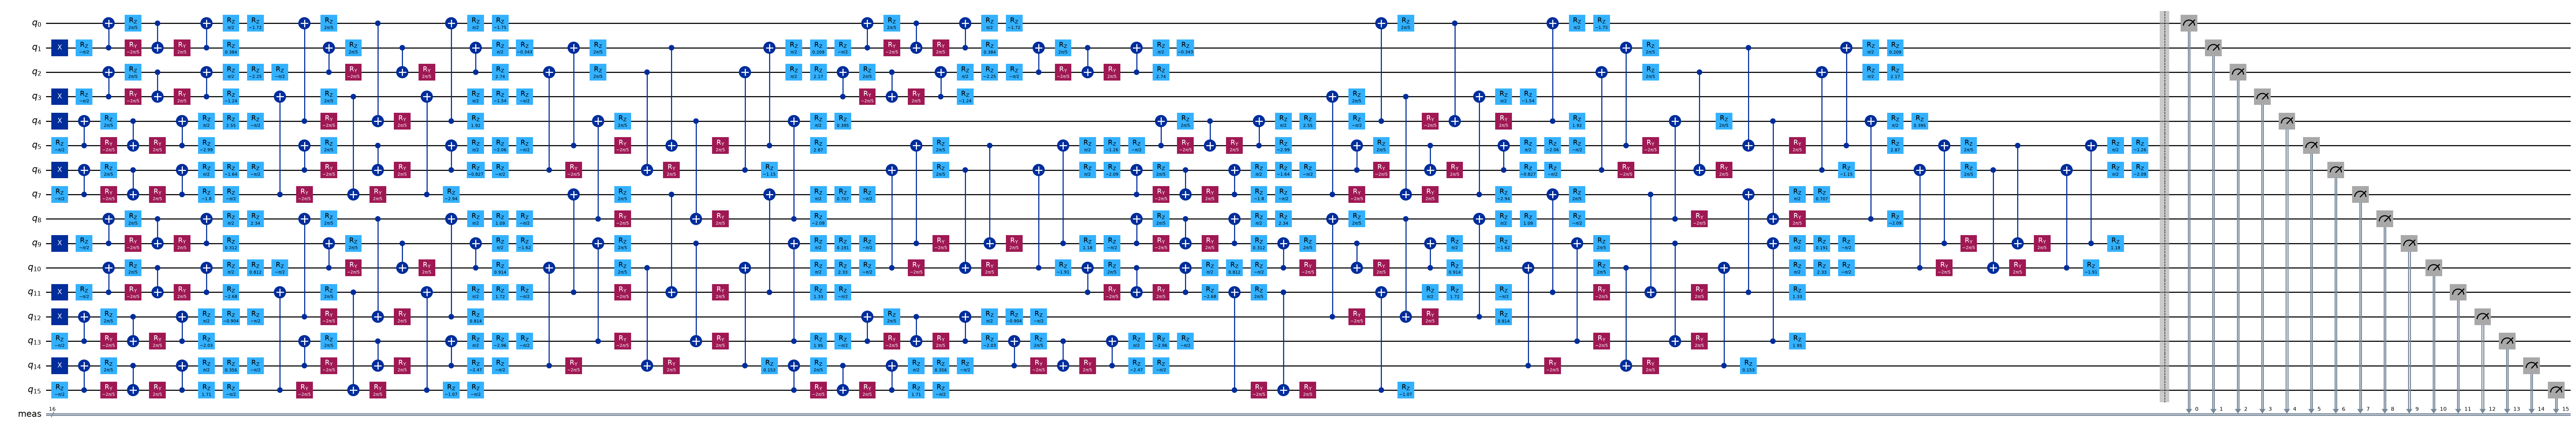

In [8]:
# simulation parameters:
num_cols = num_rows = 4
num_qubits = num_cols * num_rows
num_cycles = 2
couplings = (
    np.array([0.005, 0.01, 0.02, 0.03, 0.04, 0.05, 0.06, 0.08, 0.10, 0.125])
    * np.pi
)
disorder = sample_disorder(num_cols, num_rows, np.random.default_rng(42))

# circuit construction:
logical_circuits = [
    heisenberg_floquet_circuit(
        num_cols, num_rows, coupling, num_cycles, disorder
    )
    for coupling in couplings
]
logical_circuits[5].draw(output="mpl", fold=-1)

16 qubits: 144 CZ gates in 24 layers, for every coupling


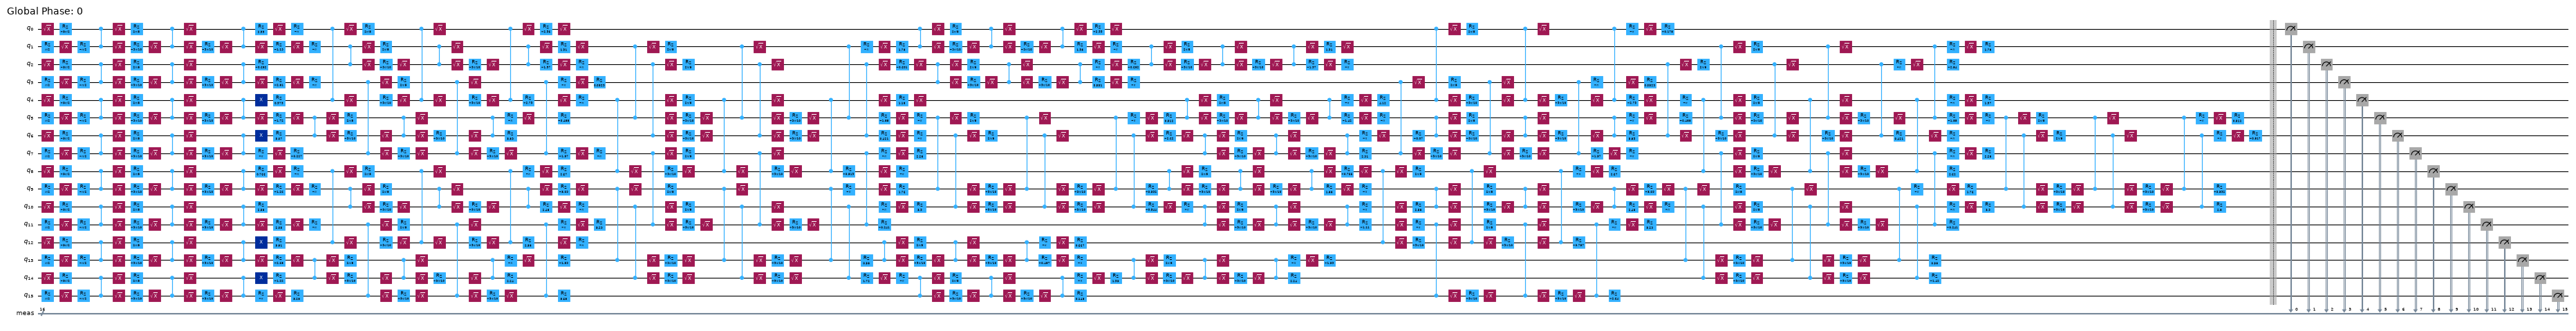

In [9]:
# transpiling the circuit:
pass_manager = generate_preset_pass_manager(
    optimization_level=3,
    basis_gates=["cz", "rz", "sx", "x"],
    seed_transpiler=7,
)
circuits = [pass_manager.run(circuit) for circuit in logical_circuits]


def two_qubit_stats(circuit):
    count = sum(1 for inst in circuit.data if inst.operation.num_qubits == 2)
    depth = circuit.depth(lambda inst: inst.operation.num_qubits == 2)
    return count, depth


stats = {two_qubit_stats(circuit) for circuit in circuits}
assert len(stats) == 1, "the CZ structure should not depend on J"
num_cz, depth = stats.pop()
print(
    f"{num_qubits} qubits: {num_cz} CZ gates in {depth} layers, for every coupling"
)
circuits[5].draw("mpl", fold=-1, scale=0.4)

A clever compiler is not needed, because the circuits (and experiment) were designed for IBM Nighthawk.

### Simulate the $4 \times 4$ lattice

For the $4 \times 4$ lattice, you can do both: compute the exact state at every coupling, and sample every circuit with 10,000 shots, as an experiment would. The shots are stored with shape (batches, shots, qubits), the same layout as the randomizations in the hardware data. Here all 10,000 shots form a single batch, so the bootstrap over batches adds no shot noise, and the error bars in the next plot show only the spread between marginal positions.

In [10]:
exact_states = [
    Statevector(
        heisenberg_floquet_circuit(
            num_cols, num_rows, c, num_cycles, disorder, measure=False
        )
    )
    for c in couplings
]

shots = 10_000
results = (
    StatevectorSampler(default_shots=shots, seed=1234).run(circuits).result()
)

# the output of the simulation for the 10 couplings
bits = [
    result.data.meas.to_bool_array(order="little").reshape(
        1, 10_000, num_qubits
    )
    for result in results
]

print(bits[0])

[[[False  True False ... False  True False]
  [False  True False ... False  True False]
  [False  True False ... False  True False]
  ...
  [False  True False ... False  True False]
  [False  True False ... False  True False]
  [False  True False ... False  True False]]]


## 2. What to measure and how to estimate it

### The IPR and the collision entropy

For a marginal $A$ of $n_A$ qubits with bitstring distribution $p_A(a)$, the quantity to estimate is the inverse participation ratio (IPR) of the marginal distribution, and from it the collision entropy:

$$
\mathrm{IPR}_A = \sum_a p_A(a)^2, \qquad S_2[A] = -\log_2 \mathrm{IPR}_A
$$

$\mathrm{IPR}_A$ is also the probability that two shots agree on the marginal. A product state has $\mathrm{IPR}_A = 1$, and a random state has $\mathrm{IPR}_A \approx 2^{-n_A}$, so $S_2$ climbs from 0 to about $n_A$ bits as the marginal becomes random.

### Estimator 1: count pairs of shots

> **Question.** How do you estimate this quantity from your shots?

<Accordion>
<AccordionItem title="Answer">


The naive estimator computes each $p(a)$ from the shots as $\hat p(a) = n_a / N$, then sums $\sum_a \hat p(a)^2$.
This estimator is biased.

$\sum_a n_a^2 / N^2$ counts every shot as agreeing with itself, which pushes the estimate up: on average it gives $\mathrm{IPR}_A + (1 - \mathrm{IPR}_A)/N$ instead of $\mathrm{IPR}_A$. Since $\mathrm{IPR}_A$ is the probability that two shots agree, count only pairs of *different* shots:


$$
\widehat{\mathrm{IPR}}_A = \frac{\sum_a n_a (n_a - 1)}{N (N - 1)}
$$

This is unbiased, and it is what `ipr_from_shots` below computes.

</AccordionItem>
</Accordion>

In [11]:
# IPR expectation values:

# refactor this function cause it does not scale
def ipr_from_shots(bits):
    # Pair-counting estimate of the IPR of a marginal: the fraction of pairs of different shots
    # that agree on it. bits holds the marginal's qubits only, with shape (randomizations, shots,
    # qubits), and all randomizations are pooled.
    n = bits.shape[-1]
    outcomes = bits @ 2 ** np.arange(
        n
    )  # each shot's marginal bitstring, read as an integer
    counts = np.bincount(outcomes.ravel())  # how often each outcome occurs
    total = counts.sum()
    return float((counts * (counts - 1)).sum() / (total * (total - 1)))


def collision_entropy(ipr):
    return -np.log2(ipr)

### Estimator 2: Parseval expansion

The IPR can also be written through the parities $\langle Z_S \rangle$ of all nonempty subsets $S$ of the marginal:

$$
\Large
\mathrm{IPR}_A = 2^{-n_A}\Bigl(1 + \sum_{\emptyset \neq S \subseteq A} \langle Z_S \rangle^2\Bigr)
$$

This form matters because error mitigation methods such as PEA work on expectation values, not on probabilities.

**One qubit:** The outcome probabilities are $p(0) = (1 + \langle Z \rangle)/2$ and $p(1) = (1 - \langle Z \rangle)/2$, so

$$
\Large
\mathrm{IPR} = p(0)^2 + p(1)^2 = \frac{1 + \langle Z \rangle^2}{2}
$$

**A $2 \times 2$ marginal:** With its qubits labeled $a, b, c, d$, the marginal has $2^4 - 1 = 15$ parities: 4 single qubits, 6 pairs, 4 triples, and the whole marginal, so

$$
\Large
\begin{aligned}
\mathrm{IPR} = \frac{1}{16} \Bigl(1
&+ \langle Z_a \rangle^2 + \langle Z_b \rangle^2 + \langle Z_c \rangle^2 + \langle Z_d \rangle^2 \\
&+ \langle Z_a Z_b \rangle^2 + \langle Z_a Z_c \rangle^2 + \langle Z_a Z_d \rangle^2 + \langle Z_b Z_c \rangle^2 + \langle Z_b Z_d \rangle^2 + \langle Z_c Z_d \rangle^2 \\
&+ \langle Z_a Z_b Z_c \rangle^2 + \langle Z_a Z_b Z_d \rangle^2 + \langle Z_a Z_c Z_d \rangle^2 + \langle Z_b Z_c Z_d \rangle^2 \\
&+ \langle Z_a Z_b Z_c Z_d \rangle^2 \Bigr)
\end{aligned}
$$

In [12]:
def parity_supports(patch):
    # All nonempty subsets S of the marginal
    return sorted(
        [
            tuple(q for k, q in enumerate(patch) if mask & (1 << k))
            for mask in range(1, 1 << len(patch))
        ],
        key=len,
    )


def parity_expectation_values(bits, supports):
    # Shot-averaged <Z_S> for every support, per randomization
    signs = 1 - 2 * bits.astype(np.int8)
    return np.stack(
        [signs[..., list(s)].prod(axis=-1).mean(axis=-1) for s in supports],
        axis=-1,
    )


# Example: the parities of a 3-qubit marginal made of lattice qubits 5, 6, and 9
print(parity_supports([5, 6, 9]))
print(f"A 3×3 marginal has {len(parity_supports(range(9)))} parities")

[(5,), (6,), (9,), (5, 6), (5, 9), (6, 9), (5, 6, 9)]
A 3×3 marginal has 511 parities


### Average over marginals

Additional useful functions: Haar values, selecting marginals, bootstrapping, and averaging.

In [13]:
# functions for the Haar values on plots:
def haar_ipr(num_patch, num_qubits):
    # Mean IPR of a marginal for Haar-random states in the sector with num_qubits // 2 ones
    weight = num_qubits // 2
    dimension = comb(num_qubits, weight)
    total = 0
    for k in range(num_patch + 1):  # k ones on the marginal
        rest = (
            comb(num_qubits - num_patch, weight - k) if weight - k >= 0 else 0
        )
        total += comb(num_patch, k) * rest * (rest + 1)
    return total / (dimension * (dimension + 1))


def haar_entropy(num_patch, num_qubits):
    return collision_entropy(haar_ipr(num_patch, num_qubits))


# definitions of positions in the lattice:
def patch_qubits(anchor, shape, num_cols):
    # Lattice indices of a rectangular marginal with its top-left corner at anchor
    (x0, y0), (width, height) = anchor, shape
    return [
        (y0 + dy) * num_cols + (x0 + dx)
        for dy in range(height)
        for dx in range(width)
    ]


def all_positions(shape, num_cols, num_rows):
    # Every placement of a (width, height) marginal on the lattice
    width, height = shape
    return [
        patch_qubits((x, y), shape, num_cols)
        for y in range(num_rows - height + 1)
        for x in range(num_cols - width + 1)
    ]


# bootstrapping for error bars:
bootstrap_rng = np.random.default_rng(0)


def bootstrap_error(statistic, *samples, axis=0, num_resamples=50):
    # Shot noise of a statistic, from resampling the randomizations (along axis of every
    # sample) with replacement
    values = []
    for _ in range(num_resamples):
        resampled = [
            np.take(
                x,
                bootstrap_rng.integers(0, x.shape[axis], x.shape[axis]),
                axis=axis,
            )
            for x in samples
        ]
        values.append(statistic(*resampled))
    return float(np.std(values, ddof=1))


# averaging the ipr over marginals:
def average_ipr(iprs, shot_errors):
    # iprs and shot_errors have shape (positions, couplings). The mean IPR over positions, and its
    # error: the spread between positions plus the shot noise of each (law of total variance)
    iprs, shot_errors = np.asarray(iprs), np.asarray(shot_errors)
    count = len(iprs)
    variance = (
        iprs.var(axis=0, ddof=1) / count
        + (shot_errors**2).sum(axis=0) / count**2
    )
    return iprs.mean(axis=0), np.sqrt(variance)

In [14]:
# Calculating exact simulation entropies:
patch_shapes = {
    "1×1": (1, 1),
    "1×2": (2, 1),
    "2×2": (2, 2),
    "2×3": (3, 2),
    "3×3": (3, 3),
}

# calculate the exact entropies:
sim_positions = {
    label: all_positions(shape, num_cols, num_rows)
    for label, shape in patch_shapes.items()
}
exact_iprs = {  # shape (positions, couplings)
    label: np.array(
        [
            [(s.probabilities(qargs=q) ** 2).sum() for s in exact_states]
            for q in qubit_lists
        ]
    )
    for label, qubit_lists in sim_positions.items()
}
exact_entropies = {
    label: collision_entropy(v.mean(axis=0))
    for label, v in exact_iprs.items()
}

# Average IPR of every shape over its positions, from the sampled shots, then the entropy
iprs_from_shots = {}  # per shape: average IPR and its error, at every coupling
entropies_from_shots = {}  # per shape: average entropy and its error, at every coupling
for label, qubit_lists in sim_positions.items():
    iprs = [[ipr_from_shots(b[:, :, q]) for b in bits] for q in qubit_lists]

    # bootstrapping over subsampling for error bars:
    errors = [
        [bootstrap_error(ipr_from_shots, b[:, :, q]) for b in bits]
        for q in qubit_lists
    ]
    ipr, ipr_error = average_ipr(iprs, errors)
    iprs_from_shots[label] = (ipr, ipr_error)
    entropies_from_shots[label] = (
        collision_entropy(ipr),
        ipr_error / (ipr * np.log(2)),
    )

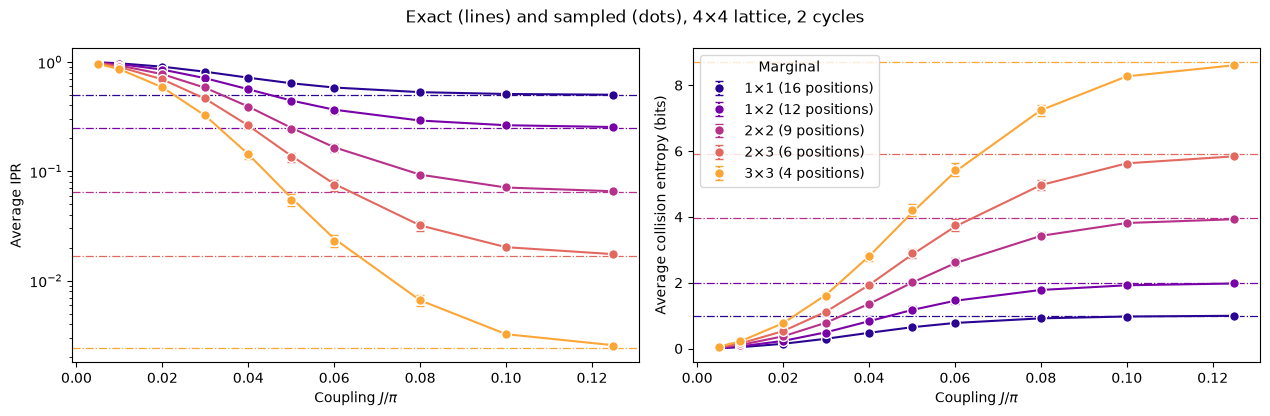

In [15]:
# Now plot the average IPR on the left, and the same averages as entropies on the right
colors = plt.cm.plasma(np.linspace(0.05, 0.8, len(patch_shapes)))
fig, (ax_ipr, ax_entropy) = plt.subplots(1, 2, figsize=(12.8, 4.2))
for (label, qubit_lists), color in zip(sim_positions.items(), colors):
    n = len(qubit_lists[0])
    ipr, ipr_error = iprs_from_shots[label]
    entropy, entropy_error = entropies_from_shots[label]
    # Left: the average IPR, with its exact value and its random-state value
    ax_ipr.axhline(haar_ipr(n, num_qubits), color=color, ls="dashdot", lw=0.9)
    ax_ipr.plot(
        couplings / np.pi, exact_iprs[label].mean(axis=0), color=color
    )
    ax_ipr.errorbar(
        couplings / np.pi,
        ipr,
        yerr=ipr_error,
        fmt="o",
        color=color,
        mec="white",
        ms=7,
        capsize=3,
        label=f"{label} ({len(qubit_lists)} positions)",
    )
    # Right: the average collision entropy
    ax_entropy.axhline(
        haar_entropy(n, num_qubits), color=color, ls="dashdot", lw=0.9
    )
    ax_entropy.plot(couplings / np.pi, exact_entropies[label], color=color)
    ax_entropy.errorbar(
        couplings / np.pi,
        entropy,
        yerr=entropy_error,
        fmt="o",
        color=color,
        mec="white",
        ms=7,
        capsize=3,
        label=f"{label} ({len(qubit_lists)} positions)",
    )
ax_ipr.set_yscale("log")
ax_ipr.set_ylabel("Average IPR")
ax_entropy.set_ylabel("Average collision entropy (bits)")
for ax in (ax_ipr, ax_entropy):
    ax.set_xlabel("Coupling $J/\\pi$")
fig.suptitle("Exact (lines) and sampled (dots), 4×4 lattice, 2 cycles")
ax_entropy.legend(title="Marginal", loc="upper left")
fig.tight_layout()
plt.show()

Every marginal shape rises smoothly toward its random-state value, and larger marginals get there at larger $J$.

## 3. Noise, and how to undo it

### A noisy simulation

Now add noise: 1% two-qubit depolarizing noise on every CZ gate and a 3% readout error on every qubit, sampled with the Qiskit Aer sampler. With 144 CZ gates in the circuit, this is much less noise than the 8×8 hardware circuits see, but enough to see what it does. The simulation uses six couplings and 4,000 shots each, and takes about 1.5 minutes.

> **Question.** Before you run it: will noise make the system look more thermalized or less thermalized?

<Accordion>
<AccordionItem title="Answer">

More. Noise scrambles the outcomes, which pushes every marginal distribution toward uniform, so the raw IPR drops and the entropy rises. Without mitigation, noise looks like thermalization that is not there, and the crossovers come out too early.

</AccordionItem>
</Accordion>

In [16]:
# define the noise model

noise_model = NoiseModel()
# two qubit depolarizing noise:
noise_model.add_all_qubit_quantum_error(depolarizing_error(0.01, 2), ["cz"])
# symmetric readout noise:
noise_model.add_all_qubit_readout_error(
    ReadoutError([[0.97, 0.03], [0.03, 0.97]])
)

# simulation is done using trajectories
noisy_sampler = AerSampler(
    default_shots=4000,
    seed=1,
    options={"backend_options": {"noise_model": noise_model}},
)

# choose a subset of J values for speed:
noisy_indices = [
    0,
    2,
    3,
    5,
    7,
    9,
]  # J/π = 0.005, 0.02, 0.03, 0.05, 0.08, 0.125
noisy_results = noisy_sampler.run(
    [circuits[k] for k in noisy_indices]
).result()

# No twirling here, so the 20 "randomizations" are just batches of 200 shots
noisy_bits = {
    k: result.data.meas.to_bool_array(order="little").reshape(
        20, 200, num_qubits
    )
    for k, result in zip(noisy_indices, noisy_results)
}

In [17]:
# Calculating noisy entropies

# Average IPR of every shape over its positions, from the noisy shots, then the entropy
noisy_iprs = {}  # per shape: average IPR and its error, at every noisy coupling
noisy_entropies = {}  # per shape: average entropy and its error, at every noisy coupling
for label, qubit_lists in sim_positions.items():
    iprs = [
        [ipr_from_shots(noisy_bits[k][:, :, q]) for k in noisy_indices]
        for q in qubit_lists
    ]

    # bootstrapping over subsampling for error bars:
    errors = [
        [
            bootstrap_error(ipr_from_shots, noisy_bits[k][:, :, q])
            for k in noisy_indices
        ]
        for q in qubit_lists
    ]
    ipr, ipr_error = average_ipr(iprs, errors)
    noisy_iprs[label] = (ipr, ipr_error)
    noisy_entropies[label] = (
        collision_entropy(ipr),
        ipr_error / (ipr * np.log(2)),
    )

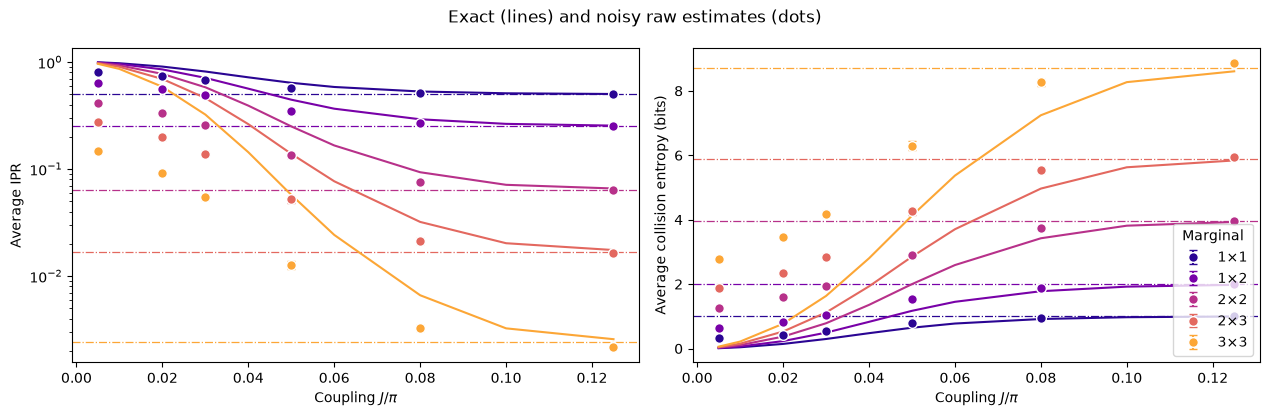

In [18]:
fig, (ax_ipr, ax_entropy) = plt.subplots(1, 2, figsize=(12.8, 4.2))
for (label, qubit_lists), color in zip(sim_positions.items(), colors):
    n = len(qubit_lists[0])
    ipr, ipr_error = noisy_iprs[label]
    entropy, entropy_error = noisy_entropies[label]
    # Left: the average IPR, with its exact value and its random-state value
    ax_ipr.axhline(haar_ipr(n, num_qubits), color=color, ls="dashdot", lw=0.9)
    ax_ipr.plot(
        couplings / np.pi, exact_iprs[label].mean(axis=0), color=color
    )
    ax_ipr.errorbar(
        couplings[noisy_indices] / np.pi,
        ipr,
        yerr=ipr_error,
        fmt="o",
        color=color,
        mec="white",
        ms=7,
        capsize=3,
        label=label,
    )
    # Right: the same averages as entropies
    ax_entropy.axhline(
        haar_entropy(n, num_qubits), color=color, ls="dashdot", lw=0.9
    )
    ax_entropy.plot(couplings / np.pi, exact_entropies[label], color=color)
    ax_entropy.errorbar(
        couplings[noisy_indices] / np.pi,
        entropy,
        yerr=entropy_error,
        fmt="o",
        color=color,
        mec="white",
        ms=7,
        capsize=3,
        label=label,
    )
ax_ipr.set_yscale("log")
ax_ipr.set_ylabel("Average IPR")
ax_entropy.set_ylabel("Average collision entropy (bits)")
for ax in (ax_ipr, ax_entropy):
    ax.set_xlabel("Coupling $J/\\pi$")
fig.suptitle("Exact (lines) and noisy raw estimates (dots)")
ax_entropy.legend(title="Marginal", loc="lower right")
fig.tight_layout()
plt.show()

### Brainstorm: how would you undo this?

<Accordion>
<AccordionItem title="Suggested approach">

At small $J$, the state is barely entangled, so the ideal answer there is cheap to compute classically, even for 64 qubits. That suggests measuring the effect of the noise at a small calibration coupling $J_0$ and correcting every other coupling with it. There are two natural ways to do that, called low-entanglement calibration (LEC):

**LEC on the IPR.** Rescale the excess of the IPR over its value for a uniform distribution, $2^{-n_A}$, by one factor per marginal:

$$
\Large
\mathrm{IPR}^{\mathrm{LEC}}_A(J) = 2^{-n_A} + R_0\bigl(\mathrm{IPR}^{\mathrm{raw}}_A(J) - 2^{-n_A}\bigr), \qquad R_0 = \frac{\mathrm{IPR}^{\mathrm{ideal}}_A(J_0) - 2^{-n_A}}{\mathrm{IPR}^{\mathrm{raw}}_A(J_0) - 2^{-n_A}}
$$

**LEC on the $\langle Z \rangle$ expectation values.** Rescale every parity of the marginal by its own factor, and rebuild the IPR with the Parseval formula:

$$
\Large
r_S = \frac{\langle Z_S \rangle^{\mathrm{ideal}}(J_0)}{\langle Z_S \rangle^{\mathrm{raw}}(J_0)}, \qquad
\mathrm{IPR}^{\mathrm{LEC}}_A(J) = 2^{-n_A}\Bigl(1 + \sum_{S} r_S^2 \, \langle Z_S \rangle^{\mathrm{raw}}(J)^2\Bigr)
$$

In the code, each squared rescaled parity is debiased by subtracting its variance, as in section 2.

Both are the same if every $r_S^2$ equals $R_0$.

</AccordionItem>
</Accordion>

> **Question.** What are the pros and cons of these methods?

<Accordion>
<AccordionItem title="Answer">

**Pros**

- **Cheap:** no extra data is needed from the device, only a classical simulation at $J_0$.
- **Uses the structure of the circuit:** the circuit depth and the CZ layers do not change with $J$, so the noise at $J_0$ is the same noise as at every other $J$.

**Cons**

- **Assumes the effect of the noise on the observables does not depend on $J$:** the noise itself is the same, but how it damps the IPR or each $\langle Z_S \rangle$ can change as $J$ grows.

</AccordionItem>
</Accordion>

### Both methods on the noisy simulation

In [19]:
# function to mitigate the IPR signal:
def mitigate_ipr_w_lec(
    ipr_raw, ipr_raw_calibration, ipr_ideal_calibration, num_patch
):
    # LEC on the IPR: one factor R0 for the excess over the uniform value
    uniform = 2.0**-num_patch
    factor = (ipr_ideal_calibration - uniform) / (
        ipr_raw_calibration - uniform
    )
    return uniform + factor * (ipr_raw - uniform)


# function used to calculate the target <Z> expectation values
def parities_from_probabilities(probabilities):
    # Ideal <Z_S> from a marginal distribution, in parity_supports order: subsets
    # by size, and in bitmask order within each size
    outcomes = np.arange(len(probabilities))
    masks = np.array(sorted(range(1, len(probabilities)), key=int.bit_count))
    signs = (-1.0) ** np.bitwise_count(outcomes[:, None] & masks[None, :])
    return np.asarray(probabilities) @ signs


# calculate boosting factors:
def lec_z_factors(calibration_parities, ideal_parities):
    # LEC on <Z>: one factor r_S per parity, from data with shape (randomizations, supports).
    return ideal_parities / calibration_parities.mean(axis=0)


# function to mitigate the IPR from <Z> expectation values:
def mitigate_ipr_w_lec_on_parities(
    parities, calibration_parities, ideal_calibration_parities, num_patch
):
    # LEC on <Z>: rescale each parity by its factor r_S = ideal / raw at J0, then rebuild the IPR
    # with Parseval. parities and calibration_parities have shape (randomizations, supports).
    # Each squared, rescaled parity is debiased by subtracting its variance, which to first
    # order combines the shot noise at J. The shot noise of r_S from J0 is omitted; including it
    # does not change the results.
    factors = lec_z_factors(calibration_parities, ideal_calibration_parities)
    mean = parities.mean(axis=0)  # mean over the twirling instances
    variance = parities.var(axis=0, ddof=1) / len(
        parities
    )  # variance of the mean
    rescaled = factors * mean
    rescaled_variance = factors**2 * variance
    return float((1 + np.sum(rescaled**2 - rescaled_variance)) / 2**num_patch)

In [20]:
def lec_estimates(patch_bits, parities, ideal, calibration, num_patch):
    # LEC on the IPR and on <Z> for one marginal position, at every coupling: values and shot
    # noise. patch_bits (the bits of the marginal only) and parities are per coupling, with
    # randomizations first.
    q_ideal = (ideal**2).sum()
    ideal_parities = parities_from_probabilities(ideal)

    def ipr_statistic(b, c):
        return mitigate_ipr_w_lec(
            ipr_from_shots(b), ipr_from_shots(c), q_ideal, num_patch
        )

    def z_statistic(p, c):
        return mitigate_ipr_w_lec_on_parities(p, c, ideal_parities, num_patch)

    values = {"LEC on IPR": [], "LEC on ⟨Z⟩": []}
    errors = {"LEC on IPR": [], "LEC on ⟨Z⟩": []}
    for k in range(len(patch_bits)):
        if (
            k == calibration
        ):  # both match the ideal value at J0 by construction
            for method in values:
                values[method].append(q_ideal)
                errors[method].append(0.0)
            continue
        values["LEC on IPR"].append(
            ipr_statistic(patch_bits[k], patch_bits[calibration])
        )
        errors["LEC on IPR"].append(
            bootstrap_error(
                ipr_statistic, patch_bits[k], patch_bits[calibration]
            )
        )
        values["LEC on ⟨Z⟩"].append(
            z_statistic(parities[k], parities[calibration])
        )
        errors["LEC on ⟨Z⟩"].append(
            bootstrap_error(z_statistic, parities[k], parities[calibration])
        )
    return values, errors


# getting all the data:
calibration_index = 0  # index of J0 = 0.005π in noisy_indices
mitigated = {
    "LEC on IPR": {},
    "LEC on ⟨Z⟩": {},
}  # per shape: (values, errors), each (positions, couplings)
for label, qubit_lists in sim_positions.items():
    n = len(qubit_lists[0])
    per_position = []
    for qubits in qubit_lists:
        supports = parity_supports(qubits)
        parities = [
            parity_expectation_values(noisy_bits[k], supports)
            for k in noisy_indices
        ]
        patch_bits = [noisy_bits[k][:, :, qubits] for k in noisy_indices]
        ideal = exact_states[noisy_indices[calibration_index]].probabilities(
            qargs=qubits
        )
        per_position.append(
            lec_estimates(patch_bits, parities, ideal, calibration_index, n)
        )
    for method in mitigated:
        mitigated[method][label] = (
            [p[0][method] for p in per_position],
            [p[1][method] for p in per_position],
        )

# Average over positions, then the entropy, for both methods
mitigated_entropies = {
    method: {} for method in mitigated
}  # per method and shape: entropy and its error
for method, by_shape in mitigated.items():
    for label, (values, errors) in by_shape.items():
        ipr, ipr_error = average_ipr(values, errors)
        mitigated_entropies[method][label] = (
            collision_entropy(ipr),
            ipr_error / (ipr * np.log(2)),
        )  # log here comes from error propagation

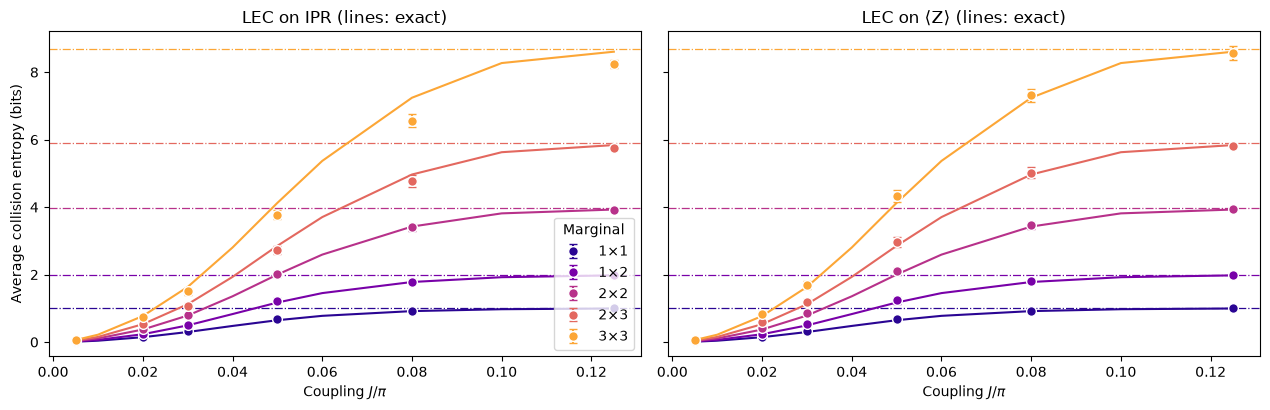

In [21]:
# Plot the data mitigated with both methods:

fig, axes = plt.subplots(1, 2, figsize=(12.8, 4.2), sharey=True)
for ax, (method, by_shape) in zip(axes, mitigated_entropies.items()):
    for (label, qubit_lists), color in zip(sim_positions.items(), colors):
        entropy, error = by_shape[label]
        ax.axhline(
            haar_entropy(len(qubit_lists[0]), num_qubits),
            color=color,
            ls="dashdot",
            lw=0.9,
        )
        ax.plot(couplings / np.pi, exact_entropies[label], color=color)
        ax.errorbar(
            couplings[noisy_indices] / np.pi,
            entropy,
            yerr=error,
            fmt="o",
            color=color,
            mec="white",
            ms=7,
            capsize=3,
            label=label,
        )
    ax.set_title(f"{method} (lines: exact)")
    ax.set_xlabel("Coupling $J/\\pi$")
axes[0].set_ylabel("Average collision entropy (bits)")
axes[0].legend(title="Marginal", loc="lower right")
fig.tight_layout()
plt.show()

# add the noisy data here too

Both methods remove most of the damage: the raw estimates in the previous plot are far too random, and the mitigated ones follow the exact curves. The differences show up for the larger marginals.

For the small marginals both methods work. For the $3 \times 3$ marginal, LEC on $\langle Z \rangle$ is clearly closer.

**Why LEC on the IPR gives too little entropy.** Too little entropy means the IPR is too big: LEC on the IPR over-inflates it. It assumes that noise damps the contribution of every $\langle Z_S \rangle$ to the IPR by the same factor. At $J_0$, every $\langle Z_S \rangle$ is close to $\pm 1$, so all strings contribute equally, and most strings have medium weight: of the 511 strings of a $3 \times 3$ marginal, 252 have weight 4 or 5, and only nine have weight 1. Noise damps a string more the higher its weight (readout error alone damps a weight-$w$ string by $0.94^w$), so the single factor $R_0$ is set mainly by the damping of medium-weight strings. As $J$ grows, the higher-weight $\langle Z_S \rangle$ decay fastest, and the IPR is carried more and more by low-weight strings, which noise damps less. Boosting them with a factor learned mainly from more heavily damped strings over-inflates the IPR. The effect grows with the size of the marginal, since a larger marginal has a wider range of weights. It is largest at intermediate $J$, after the mix of strings has shifted but while the excess of the IPR over its uniform value still matters.


**Why LEC on $\langle Z \rangle$ errs the other way.** It rescales each string by its own factor, so the shift between weights does not affect it. It only assumes that each string keeps its $J_0$ damping. As $J$ grows, each $Z_S$ spreads into higher-weight operators, which pick up more noise than at $J_0$, so the factors slightly under-correct and the entropy comes out slightly too high.

So the prediction to test on hardware is: **the larger the marginal, the more LEC on $\langle Z \rangle$ should win**. On hardware, the noise is stronger and not of a known form.

## 4. Run at scale

The hardware experiment runs an $8 \times 8$ lattice with four cycles: 64 qubits and 1,344 CZ gates in 48 layers, at nine couplings. Five things change compared with the simulation:

1. The noise has to be **learned**, which only works if the CZ layers are fixed.
2. **Twirling** turns the noise of each layer into a Pauli channel, which can be learned and amplified.
3. **Dynamical decoupling (DD)** protects idle qubits.
4. **Noise amplification** for PEA runs in the same job as the main data.
5. **MPS simulations** at small $J$ provide the classical references for LEC-based error mitigation.

The cells that need a backend only run when `RUN_ON_HARDWARE` is `True`. MPS simulations can be rerun with `COMPUTE_MPS_REFERENCES` set to `True`. The other cells run here.

In [22]:
# hardware run parameters:
num_cols_hw = num_rows_hw = 8
num_qubits_hw = num_cols_hw * num_rows_hw
num_cycles_hw = 4
couplings_hw = (
    np.array([0.005, 0.01, 0.02, 0.03, 0.05, 0.07, 0.09, 0.11, 0.125]) * np.pi
)
calibration_hw = 0  # J0 = 0.005π
disorder_hw = sample_disorder(
    num_cols_hw, num_rows_hw, np.random.default_rng(7)
)

# if running PEA:
noise_factors = np.array([1.0, 1.5, 2.0])  # PEA noise-amplification factors

### Fixed CZ layers

In [23]:
def compile_by_sublayer(
    num_cols,
    num_rows,
    coupling,
    num_cycles,
    disorder,
    pass_manager,
    layout=None,
    num_physical_qubits=None,
):
    # Compile each sublayer once and repeat it with barriers, so the CZ layers are the
    # same in every cycle and at every coupling. The registers are named explicitly
    # because register names enter Samplomatic's box hashes. Bits land in lattice order.
    num_qubits = num_cols * num_rows
    if layout is None:
        layout, num_physical_qubits = list(range(num_qubits)), num_qubits
    blocks = []
    for sublayer in disorder:
        block = QuantumCircuit(num_qubits)
        for (i, j), (h_i, h_j) in sublayer:
            heisenberg_gate(block, coupling, i, j, h_i, h_j)
        blocks.append(pass_manager.run(block))
    circuit = QuantumCircuit(
        QuantumRegister(num_physical_qubits, "q"),
        ClassicalRegister(num_qubits, "meas"),
    )
    neel_state(circuit, num_cols, num_rows, layout)
    for _ in range(num_cycles):
        for block in blocks:
            circuit.compose(block, inplace=True)
            circuit.barrier(layout)
    circuit.measure(layout, range(num_qubits))
    return circuit

### Boxes for noise learning

The Samplomatic boxing pass manager then groups each circuit into *boxes*: one per CZ layer and one for the measurements. Each box carries a reference to the noise model it needs, so you can check that all couplings share the same boxes. The next cell does this for the $8 \times 8$ circuits of the hardware run, compiled to CZ gates without a backend, and prints the boxes that noise learning will characterize.

In [24]:
from samplomatic import build
from samplomatic.transpiler import generate_boxing_pass_manager
from samplomatic.utils import find_unique_box_instructions

boxing_pass_manager = generate_boxing_pass_manager(
    enable_gates=True,  # twirl the CZ layers
    enable_measures=True,  # twirl the measurements
    inject_noise_targets="gates",  # PEA amplifies the noise of the CZ layers only
    inject_noise_strategy="uniform_modification",
)


def noise_refs(boxed_circuit):
    return sorted(
        annotation.ref
        for box in find_unique_box_instructions(boxed_circuit.data)
        for annotation in box.operation.annotations
        if hasattr(annotation, "ref")
    )


# The 8x8 hardware circuits, compiled to CZ gates on the lattice qubits (no backend needed)
compiled_8x8 = [
    compile_by_sublayer(
        num_cols_hw, num_rows_hw, c, num_cycles_hw, disorder_hw, pass_manager
    )
    for c in couplings_hw
]
boxed_8x8 = [boxing_pass_manager.run(circuit) for circuit in compiled_8x8]
assert all(
    noise_refs(b) == noise_refs(boxed_8x8[0]) for b in boxed_8x8
), "layers differ between couplings"
num_cz, depth = two_qubit_stats(compiled_8x8[0])
print(
    f"{num_qubits_hw} qubits: {num_cz} CZ gates in {depth} layers, for every coupling"
)
for box in find_unique_box_instructions(boxed_8x8[0].data):
    ops = box.operation.blocks[0].count_ops()
    print(
        f"{box.operation.num_qubits}-qubit box: {ops.get('cz', 0)} CZ, {ops.get('measure', 0)} measurements"
    )
print(
    f"All {len(boxed_8x8)} couplings share these {len(find_unique_box_instructions(boxed_8x8[0].data))} boxes"
)

64 qubits: 1344 CZ gates in 48 layers, for every coupling
64-qubit box: 32 CZ, 0 measurements
64-qubit box: 24 CZ, 0 measurements
64-qubit box: 32 CZ, 0 measurements
64-qubit box: 24 CZ, 0 measurements
64-qubit box: 0 CZ, 64 measurements
All 9 couplings share these 5 boxes


### Twirl the circuits

In every randomization, Samplomatic puts random Pauli gates before each box and the compensating gates after it, merged into the neighboring single-qubit gates. Averaged over randomizations, the noise of each layer becomes a Pauli channel, which `NoiseLearnerV3` can learn as a sparse Pauli-Lindblad model and the PEA step can amplify. Measurement twirling randomly flips bits before readout. The flips are undone in software, which makes the readout noise symmetric and is the basis of the readout correction (TREX).

### The hardware workflow

Choose the qubits, compile the circuits, then learn the noise and run the sweep. These cells are switched off here.

**Choose the qubits.** Nighthawk's square grid holds the $8 \times 8$ lattice without SWAP gates. The cell scores every $8 \times 8$ rectangle of the grid by its reported CZ and readout errors and takes the best.

In [25]:
def square_layouts(backend, side):
    # Every side x side rectangle of the square qubit grid that supports all bonds
    target = backend.target

    def has_cz(a, b):
        return (a, b) in target["cz"] or (b, a) in target["cz"]

    stride = next(
        s
        for s in (10, 12)
        if all(has_cz(q, q + s) for q in range(backend.num_qubits - s))
    )
    layouts = []
    for y0 in range(backend.num_qubits // stride - side + 1):
        for x0 in range(stride - side + 1):
            layout = [
                stride * (y0 + y) + x0 + x
                for y in range(side)
                for x in range(side)
            ]
            bonds = [
                bond
                for layer in brickwork_layers(side, side)
                for bond in layer
            ]
            if all(has_cz(layout[i], layout[j]) for i, j in bonds):
                layouts.append(((x0, y0), layout))
    return layouts


def layout_score(backend, layout, side, uses_per_bond):
    # Minus the summed log-fidelity of the bonds (each used uses_per_bond times) and readouts
    properties, target = backend.properties(), backend.target
    cz_errors = []
    for i, j in (
        bond for layer in brickwork_layers(side, side) for bond in layer
    ):
        pair = (
            (layout[i], layout[j])
            if (layout[i], layout[j]) in target["cz"]
            else (layout[j], layout[i])
        )
        cz_errors.append(properties.gate_error("cz", pair))
    readout_errors = [properties.readout_error(q) for q in layout]
    if max(cz_errors) >= 0.5 or max(readout_errors) >= 0.25:
        return np.inf  # an unusable qubit or bond
    return float(
        -uses_per_bond * np.log1p(-np.array(cz_errors)).sum()
        - np.log1p(-np.array(readout_errors)).sum()
    )


if RUN_ON_HARDWARE:
    from qiskit_ibm_runtime import QiskitRuntimeService

    def holds_lattice(backend):
        try:
            return bool(square_layouts(backend, num_cols_hw))
        except (KeyError, StopIteration):
            return False

    service = QiskitRuntimeService()
    candidates = [
        b
        for b in service.backends(operational=True, simulator=False)
        if holds_lattice(b)
    ]
    backend = min(candidates, key=lambda b: b.status().pending_jobs)
    score, origin, initial_layout = min(
        (
            layout_score(backend, layout, num_cols_hw, 3 * num_cycles_hw),
            origin,
            layout,
        )
        for origin, layout in square_layouts(backend, num_cols_hw)
    )
    print(f"{backend.name}: origin {origin}, score {score:.2f}")

**Compile.** The same steps as above on the chosen qubits, followed by `build`, which turns each boxed circuit into a template circuit and a *samplex*, the recipe for drawing the twirling gates and the injected noise. DD is added to the templates.

In [26]:
if RUN_ON_HARDWARE:
    from qiskit_ibm_runtime.executor.dynamical_decoupling import (
        generate_dd_pass_manager,
    )
    from qiskit_ibm_runtime.options import DynamicalDecouplingOptions

    # PEA structure functions:
    target_pass_manager = generate_preset_pass_manager(
        target=backend.target,
        optimization_level=3,
        initial_layout=initial_layout,
        routing_method="none",
        seed_transpiler=7,
    )
    boxed_hw = [
        boxing_pass_manager.run(
            compile_by_sublayer(
                num_cols_hw,
                num_rows_hw,
                coupling,
                num_cycles_hw,
                disorder_hw,
                target_pass_manager,
                layout=initial_layout,
                num_physical_qubits=backend.num_qubits,
            )
        )
        for coupling in couplings_hw
    ]
    assert all(noise_refs(b) == noise_refs(boxed_hw[0]) for b in boxed_hw)
    unique_boxes_hw = find_unique_box_instructions(boxed_hw[0].data)

    # DD pass:
    dd_pass_manager = generate_dd_pass_manager(
        backend,
        DynamicalDecouplingOptions(
            enable=True,
            sequence_type="XY4",
            scheduling_method="alap",
            extra_slack_distribution="middle",
            skip_reset_qubits=False,
        ),
    )
    templates = []
    for circuit in boxed_hw:
        template, samplex = build(circuit)
        templates.append((dd_pass_manager.run(template), samplex))

**Learn the noise and run the sweep.** One `NoiseLearnerV3` job learns all five boxes: a Pauli-Lindblad model for each of the four CZ layers, and the readout noise of the measurement box. Then one `QuantumProgram` holds all nine couplings. Each item gets its template, its samplex, the learned noise models, and three noise scales. A scale of 0 is the unamplified data for both LEC methods. Scales of 0.5 and 1 add 50% and 100% of the learned noise for PEA, which extrapolates back to zero noise. This uses about 40 seconds of QPU time.

In [27]:
if RUN_ON_HARDWARE:
    from qiskit_ibm_runtime import Executor, NoiseLearnerV3, QuantumProgram

    # Learn the noise of the five boxes
    learner = NoiseLearnerV3(backend)
    learner.options.num_randomizations = 32
    learner.options.shots_per_randomization = 128
    # Up to 24 layer pairs, the depth of the 48-layer circuits
    learner.options.layer_pair_depths = [0, 1, 2, 4, 16, 24]
    learner_job = learner.run(unique_boxes_hw)
    print("Noise learning job:", learner_job.job_id())

    # Run the sweep, with the learned noise amplified by each of the noise factors
    noise_maps = learner_job.result().to_dict(
        instructions=unique_boxes_hw, require_refs=False
    )
    program = QuantumProgram(shots=200)
    for template, samplex in templates:
        program.append_samplex_item(
            template,
            samplex=samplex,
            samplex_arguments={
                "pauli_lindblad_maps": noise_maps,
                **{
                    f"noise_scales.{ref}": (noise_factors - 1).reshape(-1, 1)
                    for ref in noise_maps
                },
            },
            shape=(len(noise_factors), 200),  # noise scales x randomizations
        )
    executor_job = Executor(backend).run(program)
    print("Executor job:", executor_job.job_id())
    # Section 5 converts the results of these two jobs and saves them

## 5. The hardware data

This section explores how the previous methods perform on real hardware data from a Nighthawk processor.

### Load the run

With `RUN_ON_HARDWARE` set to `True`, the next cell converts the results of the two jobs from section 4 and saves them to `data/hardware_run_new.npz`, in the same format as the saved run, so the new run can be analyzed again later. Otherwise it loads the saved run from `data/hardware_run.npz`. The bits are packed along the qubit axis to save space.


If the kernel restarts while the jobs run, do not submit them again. Rerun the cells before the last call in section 4, check that the same qubits are chosen, and set `learner_job` and `executor_job` to `service.job(job_id)` with the job IDs that were printed out in section 4.

In [28]:
if RUN_ON_HARDWARE:

    def unflip(item_result):
        # Undo the measurement twirling of an Executor item: flip back the bits that were flipped
        return item_result["meas"] ^ item_result["measurement_flips.meas"]

    learner_result = learner_job.result()
    raw_bits = [unflip(item) for item in executor_job.result()]

    # The learned readout map indexes the measured qubits in ascending physical order;
    # relabel it to lattice order
    measurement_box_index = next(
        k
        for k, box in enumerate(unique_boxes_hw)
        if "measure" in box.operation.blocks[0].count_ops()
    )
    measurement_box = next(
        inst
        for inst in boxed_hw[0].data
        if inst.operation.name == "box"
        and "measure" in inst.operation.blocks[0].count_ops()
    )
    measured = sorted(
        boxed_hw[0].find_bit(q).index for q in measurement_box.qubits
    )
    lattice_index = {physical: q for q, physical in enumerate(initial_layout)}
    readout_map = (
        learner_result[measurement_box_index]
        .to_pauli_lindblad_map()
        .apply_layout([lattice_index[p] for p in measured], num_qubits_hw)
    )

    # Save the run in the same format as the saved run, so it can be analyzed again later
    terms = readout_map.to_sparse_list()
    np.savez_compressed(
        "data/hardware_run_new.npz",
        bits=np.packbits(np.stack(raw_bits), axis=-1, bitorder="little"),
        labels=np.array([label for label, _, _ in terms]),
        indices=np.concatenate(
            [np.asarray(support) for _, support, _ in terms]
        ),
        rates=np.array([rate for _, _, rate in terms]),
        physical_qubits=np.array(initial_layout),
        couplings_over_pi=couplings_hw / np.pi,
        noise_factors=noise_factors,
    )
else:
    saved = np.load(
        "data/hardware_run.npz"
    )  # or data/hardware_run_new.npz, for a new run
    raw_bits = list(
        np.unpackbits(
            saved["bits"], axis=-1, count=num_qubits_hw, bitorder="little"
        ).astype(bool)
    )
    labels = [str(label) for label in saved["labels"]]
    indices = np.split(
        saved["indices"], np.cumsum([len(label) for label in labels])[:-1]
    )
    readout_map = PauliLindbladMap.from_sparse_list(
        list(zip(labels, indices, saved["rates"])), num_qubits_hw
    )

print(f"{len(raw_bits)} couplings, bits per coupling: {raw_bits[0].shape}")
print(
    f"Readout noise: {readout_map.num_terms} terms on {readout_map.num_qubits} qubits"
)

9 couplings, bits per coupling: (3, 200, 200, 64)
Readout noise: 64 terms on 64 qubits


### Classical references

Both LEC methods need the ideal marginal distributions at $J_0 = 0.005\pi$, and testing them needs ideal values at the held-out couplings $J = 0.01\pi$ and $0.02\pi$. These come from matrix product state (MPS) simulations, saved for every placement of each marginal shape on the lattice, as in the paper, and for every non-overlapping $2 \times 2$ block at $J_0$. At $J_0$ they converge at bond dimension $\chi = 64$. At $J = 0.01\pi$ and $0.02\pi$ they use $\chi = 128$, and at $0.02\pi$ they still change by up to about 13% from $\chi = 64$ for $3 \times 3$ marginals, so treat them as approximate there. The next cell computes them if `COMPUTE_MPS_REFERENCES` is `True`, which takes about 18 minutes, and otherwise loads the saved results, keyed by coupling index, bond dimension, and marginal.

In [29]:
# Every placement of every shape on the 8x8 lattice
positions = {
    label: all_positions(shape, num_cols_hw, num_rows_hw)
    for label, shape in patch_shapes.items()
}
reference_settings = [
    (calibration_hw, 32),
    (calibration_hw, 64),
    (1, 128),
    (2, 64),
    (2, 128),
]  # (coupling, χ)

if COMPUTE_MPS_REFERENCES:

    def mps_patch_probabilities(coupling, patches, bond_dimension):
        # Distributions of the given marginals after the 8x8 circuit, from an MPS simulation
        simulator = AerSimulator(
            method="matrix_product_state",
            matrix_product_state_max_bond_dimension=bond_dimension,
            matrix_product_state_truncation_threshold=1e-12,
        )
        circuit = heisenberg_floquet_circuit(
            num_cols_hw,
            num_rows_hw,
            coupling,
            num_cycles_hw,
            disorder_hw,
            measure=False,
        )
        circuit = generate_preset_pass_manager(
            optimization_level=1, basis_gates=["cx", "u"], seed_transpiler=7
        ).run(circuit)
        for label, qubits in patches.items():
            circuit.save_probabilities(qubits, label=label)
        data = simulator.run(circuit, shots=1).result().data(0)
        return {label: np.asarray(data[label]) for label in patches}

    placements = {
        f"{label} {k}": qubits
        for label, patch_list in positions.items()
        for k, qubits in enumerate(patch_list)
    }
    tiles = {
        f"site {q}": [q] for q in range(num_qubits_hw)
    } | {  # for the lattice map at J0
        f"block {x},{y}": patch_qubits((2 * x, 2 * y), (2, 2), num_cols_hw)
        for y in range(num_rows_hw // 2)
        for x in range(num_cols_hw // 2)
    }
    computed = {}
    for index, chi in reference_settings:
        targets = (
            placements | tiles
            if (index, chi) == (calibration_hw, 64)
            else placements
        )
        for key, p in mps_patch_probabilities(
            couplings_hw[index], targets, chi
        ).items():
            computed[f"{index}/{chi}/{key}"] = p
    np.savez_compressed("data/mps_references_all.npz", **computed)
    saved = computed
else:
    saved = np.load("data/mps_references_all.npz")

references = {}  # (coupling index, bond dimension) -> {marginal key: distribution}
for name in saved:
    index, chi, key = name.split("/", 2)
    references.setdefault((int(index), int(chi)), {})[key] = saved[name]

### Data quality: faulty couplers / qubits

First, look at the lowest coupling, $J_0$, where the expectation values should be close to the Néel checkerboard.

In [30]:
# <Z> of every site at J0: the MPS reference, and the hardware data at noise factor 1
z_reference = np.array(
    [
        parities_from_probabilities(
            references[(calibration_hw, 64)][f"site {q}"]
        )[0]
        for q in range(num_qubits_hw)
    ]
)
z_measured = 1 - 2 * raw_bits[calibration_hw][0].mean(axis=(0, 1))

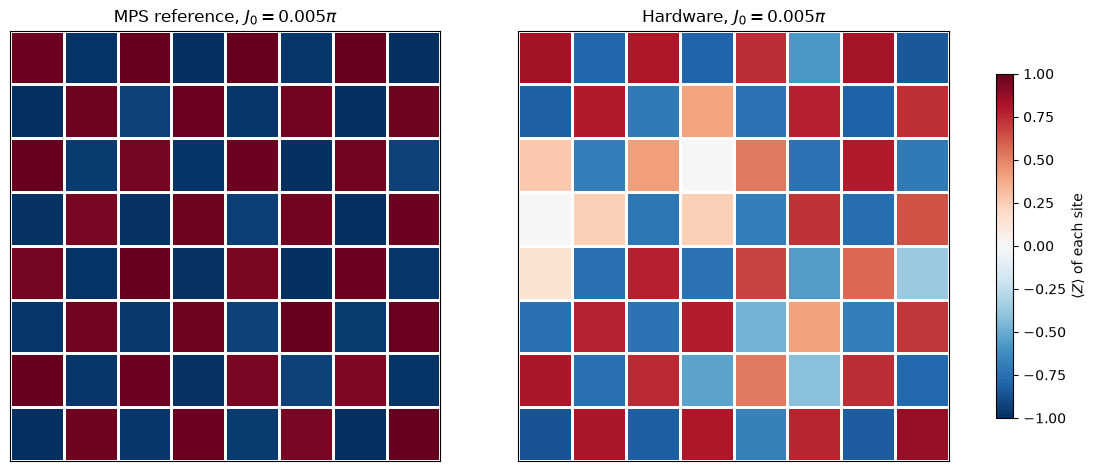

In [31]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4.6), layout="constrained")
fig.get_layout_engine().set(wspace=0.12)  # white space between the two panels
edges = np.arange(num_cols_hw + 1) - 0.5
for ax, values, title in zip(
    axes, (z_reference, z_measured), ("MPS reference", "Hardware")
):
    mesh = ax.pcolormesh(
        edges,
        edges,
        values.reshape(num_rows_hw, num_cols_hw),
        cmap="RdBu_r",
        vmin=-1,
        vmax=1,
        edgecolors="white",
    )
    ax.set_aspect("equal")
    ax.invert_yaxis()
    ax.set_xticks([])
    ax.set_yticks([])
    ax.set_title(
        f"{title}, $J_0 = {couplings_hw[calibration_hw] / np.pi:g}\\pi$"
    )
fig.colorbar(
    mesh, ax=axes, shrink=0.8, label=r"$\langle Z \rangle$ of each site"
)
plt.show()

> **Question.** Looking at the hardware map, what stands out?

<Accordion>
<AccordionItem title="Answer">

The pale sites, which have lost almost all of their signal although the state at $J_0$ is close to the Néel state. They matter because LEC divides by whatever signal survives at $J_0$: a qubit with almost no signal gives a huge, noisy correction factor, and a few such qubits can dominate every marginal that contains them.

A rule that uses only the data: A qubit is faulty if its single-qubit IPR at $J_0$ is within 0.02 of $1/2$, the value for a fully mixed qubit. Since the IPR of one qubit is $(1 + \langle Z \rangle^2)/2$, this flags qubits with $|\langle Z \rangle| < 0.2$. Marginals that contain a flagged site are left out below.

</AccordionItem>
</Accordion>

In [32]:
site_iprs = np.array(
    [
        ipr_from_shots(raw_bits[calibration_hw][0][:, :, [q]])
        for q in range(num_qubits_hw)
    ]
)
flagged = {q for q in range(num_qubits_hw) if abs(site_iprs[q] - 0.5) < 0.02}
print(
    f"Median single-qubit IPR at J0: {np.median(site_iprs):.2f}; flagged lattice sites {sorted(flagged)}"
)

Median single-qubit IPR at J0: 0.77; flagged lattice sites [19, 24, 32]


### Select the marginals to average

The next cell shows which placements of each shape enter the averages below: every placement in the bulk of the lattice without a flagged site (red crosses). Placements that touch the edge (shaded) are left out. Edge qubits have fewer bonds, so they scramble more slowly. Averaged on their own, they cross over a full step of $J$ later than bulk placements, for every shape and method. Each averaged placement has its own box, colored by placement.

In [33]:
def touches_edge(qubits):
    # Whether a placement includes a site on the edge of the lattice
    return any(
        q % num_cols_hw in (0, num_cols_hw - 1)
        or q // num_cols_hw in (0, num_rows_hw - 1)
        for q in qubits
    )


# The placements of each shape that enter the averages: in the bulk, and without a flagged site
kept_placements = {
    label: [
        k
        for k, qubits in enumerate(patch_list)
        if not touches_edge(qubits) and not set(qubits) & flagged
    ]
    for label, patch_list in positions.items()
}

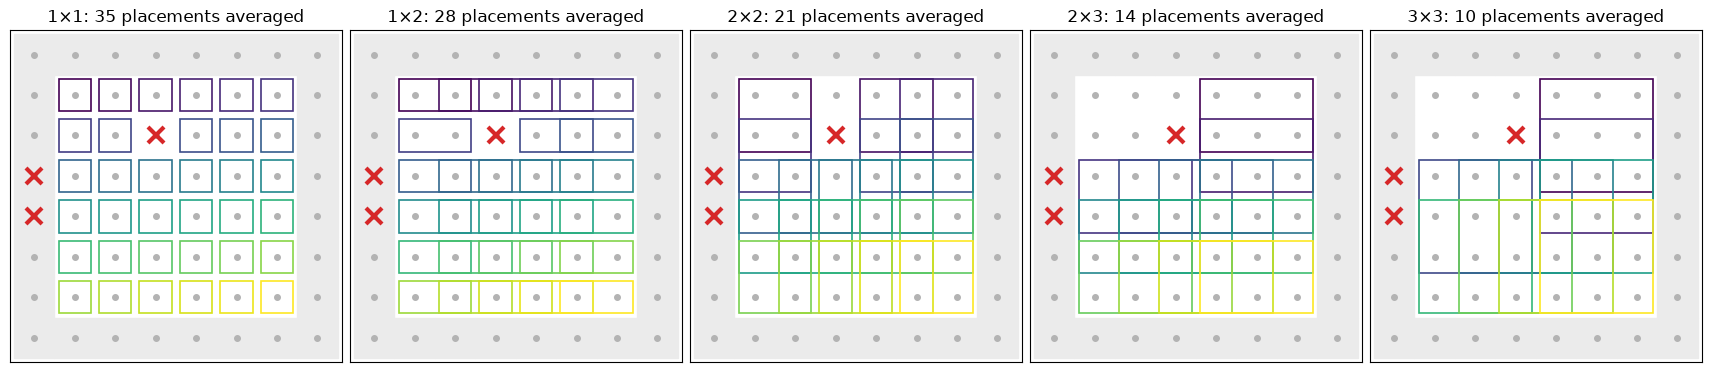

In [34]:
placement_cmap = plt.get_cmap("viridis")
fig, axes = plt.subplots(
    1, len(positions), figsize=(17, 4.4), layout="constrained"
)
for ax, (label, patch_list) in zip(axes, positions.items()):
    width, height = patch_shapes[label]
    for q in range(num_qubits_hw):
        x, y = q % num_cols_hw, q // num_cols_hw
        if touches_edge([q]):  # shade the edge of the lattice
            ax.add_patch(
                plt.Rectangle(
                    (x - 0.5, y - 0.5), 1, 1, color="0.92", zorder=0
                )
            )
        ax.plot(x, y, "o", color="0.7", ms=4, zorder=1)
    kept = kept_placements[label]
    for i, k in enumerate(kept):
        qubits = patch_list[k]
        x0, y0 = (
            qubits[0] % num_cols_hw,
            qubits[0] // num_cols_hw,
        )  # top-left site of the placement
        ax.add_patch(
            plt.Rectangle(
                (x0 - 0.4, y0 - 0.4),
                width - 0.2,
                height - 0.2,
                fill=False,
                lw=1.2,
                ec=placement_cmap(i / max(len(kept) - 1, 1)),
                zorder=2,
            )
        )
    for q in flagged:
        ax.plot(
            q % num_cols_hw,
            q // num_cols_hw,
            "x",
            color="#d62728",
            ms=11,
            mew=3,
            zorder=3,
        )
    ax.set_xlim(-0.6, num_cols_hw - 0.4)
    ax.set_ylim(num_rows_hw - 0.4, -0.6)
    ax.set_aspect("equal")
    ax.set_xticks([])
    ax.set_yticks([])
    ax.set_title(f"{label}: {len(kept)} placements averaged")
plt.show()

### PEA

The third method needs no classical reference. For each parity, take the values at noise factors 1, 1.5, and 2, divide out the learned readout damping (TREX), fit an exponential in the noise factor, and extrapolate to zero noise. Parities that change sign or are nearly zero get a straight-line fit. Subtracting the variance needs a reliable estimate of it, which is easy for raw and rescaled parities but not for the output of a nonlinear fit with clipping and fallbacks. PEA therefore uses the other standard way to remove the bias of a square. Extrapolate each half of the randomizations separately and multiply the two independent estimates.

In [35]:
def readout_fidelity(support):
    # Damping of <Z_S> by the learned readout noise
    pauli = QubitSparsePauli.from_sparse_label(
        ("Z" * len(support), list(support)), num_qubits_hw
    )
    return readout_map.pauli_fidelity(pauli)


def extrapolate_to_zero(values):
    # Fit a * exp(b * factor) to each column of values (noise factors first), or a line
    # where the values change sign or come within 1e-3 of zero
    result = np.polynomial.polynomial.polyfit(noise_factors, values, 1)[0]
    sign = np.sign(values[0])
    usable = np.all(np.sign(values) == sign, axis=0) & (
        np.abs(values).min(axis=0) > 1e-3
    )
    if usable.any():
        log_fit = np.polynomial.polynomial.polyfit(
            noise_factors, np.log(np.abs(values[:, usable])), 1
        )
        result[usable] = sign[usable] * np.exp(log_fit[0])
    return result


def pea_ipr(parities, fidelities, num_patch):
    # parities has shape (noise factors, randomizations, supports). Extrapolate the two
    # halves of the randomizations separately; their errors are independent, so the
    # product of the two estimates of each parity has no shot-noise bias
    def zero_noise(p):
        # A parity cannot exceed 1 in magnitude, so cap the extrapolated values there
        return np.clip(
            extrapolate_to_zero(p.mean(axis=1) / fidelities), -1, 1
        )

    half = parities.shape[1] // 2
    first, second = (
        zero_noise(parities[:, :half]),
        zero_noise(parities[:, half:]),
    )
    return float((1 + np.dot(first, second)) / 2**num_patch)

### All four estimates, and the crossovers

The next function computes the raw, LEC-on-IPR, LEC-on-$\langle Z \rangle$, and PEA estimates of the IPR of one marginal position at every coupling. It also estimates the shot noise of each, by bootstrapping the randomizations. The cell runs it for every placement that enters the averages, which takes about a minute and a half.

In [36]:
def estimate_iprs(qubits, key):
    # Raw, LEC-on-IPR, LEC-on-<Z>, and PEA IPRs of one marginal position at every coupling,
    # with the shot noise of each from a bootstrap over the randomizations
    n = len(qubits)
    supports = parity_supports(qubits)
    # Parities with shape (noise factors, randomizations, supports), per coupling
    parities = [
        np.stack([parity_expectation_values(b, supports) for b in bits])
        for bits in raw_bits
    ]
    patch_bits = [
        bits[0][:, :, qubits] for bits in raw_bits
    ]  # noise factor 1
    values, errors = lec_estimates(
        patch_bits,
        [p[0] for p in parities],
        references[(calibration_hw, 64)][key],
        calibration_hw,
        n,
    )
    fidelities = np.array([readout_fidelity(s) for s in supports])

    def pea_statistic(p):
        return pea_ipr(p, fidelities, n)

    values["raw"] = [ipr_from_shots(b) for b in patch_bits]
    errors["raw"] = [bootstrap_error(ipr_from_shots, b) for b in patch_bits]
    values["PEA"] = [pea_statistic(p) for p in parities]
    errors["PEA"] = [
        bootstrap_error(pea_statistic, p, axis=1) for p in parities
    ]  # randomizations are axis 1
    return {m: np.array(v) for m, v in values.items()}, {
        m: np.array(e) for m, e in errors.items()
    }


methods = ["LEC on IPR", "LEC on ⟨Z⟩", "PEA"]
method_colors = {
    "LEC on IPR": "#2a78d6",
    "LEC on ⟨Z⟩": "#1baf7a",
    "PEA": "#eb6834",
}
iprs, ipr_errors = {}, {}
for label, patch_list in positions.items():
    for k in kept_placements[label]:
        iprs[label, k], ipr_errors[label, k] = estimate_iprs(
            patch_list[k], f"{label} {k}"
        )
print(f"{len(iprs)} clean marginal positions")

108 clean marginal positions


In [37]:
def crossover_coupling(couplings, entropies, haar, tolerance=0.1):
    # Smallest coupling whose entropy is within tolerance of the random-state value
    for coupling, entropy in zip(couplings, entropies):
        if entropy >= haar - tolerance:
            return coupling
    return None


def reference_ipr(index, chi, key):
    # IPR of the MPS distribution of a marginal
    return float((references[(index, chi)][key] ** 2).sum())


mps_settings = [
    (calibration_hw, 64),
    (1, 128),
    (2, 128),
]  # (coupling index, bond dimension)
panels = ["raw", *methods]

# Average IPR of every shape over its clean placements, then the entropy and the crossover
hw_entropies = {
    method: {} for method in panels
}  # per method and shape: average entropy and its error
crossovers = {method: {} for method in panels}
mps_entropies = {}  # per shape: MPS entropy, averaged over the same placements, at mps_settings
for label, patch_list in positions.items():
    haar = haar_entropy(len(patch_list[0]), num_qubits_hw)
    keys = [(shape, k) for (shape, k) in iprs if shape == label]
    mps_entropies[label] = [
        collision_entropy(
            np.mean([reference_ipr(j, chi, f"{label} {k}") for _, k in keys])
        )
        for j, chi in mps_settings
    ]
    for method in panels:
        ipr, ipr_error = average_ipr(
            [iprs[key][method] for key in keys],
            [ipr_errors[key][method] for key in keys],
        )
        entropy = collision_entropy(ipr)
        hw_entropies[method][label] = (entropy, ipr_error / (ipr * np.log(2)))
        crossovers[method][label] = crossover_coupling(
            couplings_hw, entropy, haar
        )

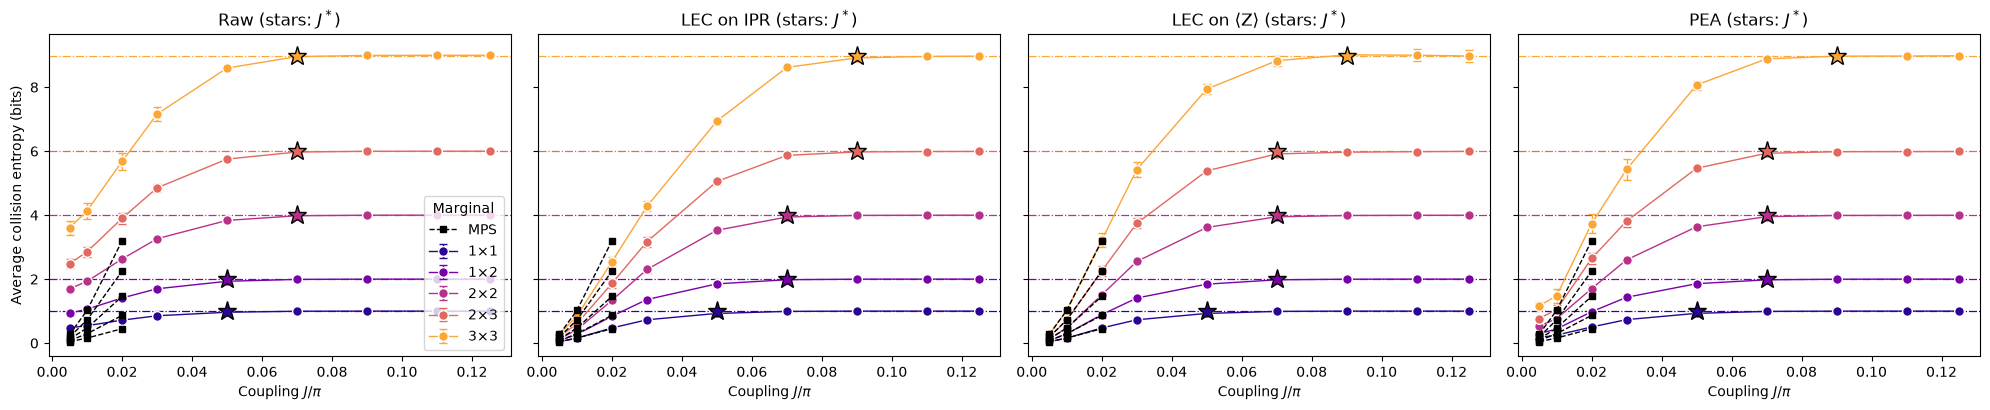

In [38]:
fig, axes = plt.subplots(
    1, len(panels), figsize=(5 * len(panels), 4.2), sharey=True
)
for (label, patch_list), color in zip(positions.items(), colors):
    haar = haar_entropy(len(patch_list[0]), num_qubits_hw)
    for ax, method in zip(axes, panels):
        entropy, error = hw_entropies[method][label]
        ax.errorbar(
            couplings_hw / np.pi,
            entropy,
            yerr=error,
            fmt="o-",
            color=color,
            mec="white",
            ms=7,
            lw=1,
            capsize=3,
            label=label,
        )
        ax.plot(
            couplings_hw[[j for j, _ in mps_settings]] / np.pi,
            mps_entropies[label],
            "s--",
            color="black",
            ms=4,
            lw=1,
            label="MPS" if label == "3×3" else None,
            zorder=4,
        )
        ax.axhline(haar, color=color, ls="dashdot", lw=0.9)
        if crossovers[method][label]:
            ax.plot(
                crossovers[method][label] / np.pi,
                haar,
                "*",
                ms=14,
                color=color,
                mec="black",
                zorder=3,
            )
for ax, method in zip(axes, panels):
    ax.set_title(f"{'Raw' if method == 'raw' else method} (stars: $J^*$)")
    ax.set_xlabel("Coupling $J/\\pi$")
axes[0].set_ylabel("Average collision entropy (bits)")
axes[0].legend(title="Marginal", loc="lower right")
fig.tight_layout()
plt.show()

## Wrap-up

What it took to run an experiment of this size:

- **Circuits whose structure does not depend on $J$**, compiled one sublayer at a time, so one noise model serves the whole sweep.
- **Estimators that work from bitstrings**: pair counting for the IPR of a marginal, and the Parseval form, with the variance subtracted from each squared parity, when the inputs are mitigated expectation values.
- **A cheap classical anchor**: the ideal state at small $J$ calibrates the noise, and held-out couplings test the calibration. Calibrating each $\langle Z_S \rangle$ separately, rather than the IPR as a whole, is what makes the large marginals agree.
- **IBM tools for the heavy lifting**: Samplomatic boxes and twirling, `NoiseLearnerV3`, dynamical decoupling, and one `Executor` job with noise amplification for PEA.
- **Data-quality checks** that use only the data.

**Next steps.** To go further with mitigation, see the [probabilistic error amplification](/docs/tutorials/probabilistic-error-amplification) and [PEC with shaded lightcones](/docs/tutorials/pec-with-shaded-lightcones) tutorials.